# Classificação de batimentos cardíacos: avaliação honesta por paciente

Projeto final da Trilha de Trainees Insper AI (Tom e Renata).

**Pergunta:** quanto do desempenho "bonito" (~98-99%) de classificadores de arritmia some quando o teste usa pacientes que o modelo nunca viu, principalmente na classe S? E o que ajuda a recuperar parte dessa queda?

**Como ler:** cada seção tem o título numa célula separada. No VS Code dá para recolher a seção e ver só os títulos. O plano completo e o log de decisões estão no `CLAUDE.md`.

## Glossário

**Classes de batimento** (padrão AAMI). Contagens = as 44 gravações do nosso dataset.

| Classe | Nome | O que é, em termos simples | Símbolos MIT-BIH | Batimentos |
|---|---|---|---|---|
| **N** | Normal | Batimento que segue o caminho elétrico normal do coração. Inclui variações como bloqueio de ramo (L, R) | N, L, R, e, j | 90.042 |
| **S** | Supraventricular ectópico | Batimento que nasce **antes da hora**, num ponto acima dos ventrículos (átrios ou junção). O formato é parecido com o do N; o que muda é o momento | A, a, J, S | 2.779 |
| **V** | Ventricular ectópico | Batimento que nasce antes da hora **nos próprios ventrículos**. A onda fica larga e com formato estranho | V, E | 7.007 |
| **F** | Fusão | Um batimento normal e um ventricular acontecem quase juntos e as ondas se misturam | F | 802 |
| **Q** | Desconhecido | Batimentos não classificáveis (no MIT-BIH completo, também os de marcapasso). Quase some aqui e sai da avaliação | /, f, Q | 15 |

**Termos usados no notebook**

| Termo | Significado |
|---|---|
| **Pico R** | O pico alto e fino de cada batimento no ECG. Os cardiologistas marcaram a posição de cada um. |
| **Um dado = um batimento** | Cada pico R anotado vira um exemplo: uma janela de 1 s do sinal ao redor dele, com a classe que o cardiologista deu. O modelo nunca vê a gravação inteira. |
| **Intervalo RR** | Tempo entre dois picos R seguidos, ou seja, entre dois batimentos. RR de 0,8 s = 75 batimentos por minuto (60 ÷ 0,8). |
| **Derivação MLII** | Um dos "ângulos" de onde o ECG mede o coração. Cada gravação tem dois; usamos a MLII, a mais comum nos artigos. |
| **DS1 / DS2** | Grupos de 22 pacientes cada (de Chazal et al., 2004). DS1 = treino, DS2 = teste. Nenhum paciente aparece nos dois. |
| **Split aleatório × por paciente** | Aleatório: sorteia batimentos, então o mesmo paciente cai no treino e no teste. Por paciente: o teste só tem pessoas que o modelo nunca viu. |

## 0. Status do projeto

Atualizar sempre que uma etapa mudar.

| Seção | Status |
|---|---|
| 1. Configuração | Pronto, rodado |
| 2. Teste de leitura (gravação 100) | Pronto, rodado (05/11) |
| 3. Montagem do dataset | Pronto, rodado (05/11). Escolhas provisórias, a confirmar com o Tom |
| 4. EDA | Pronto, rodado (05/11) |
| 5. Divisão dos dados | A fazer |
| 6. Experimentos E0-E5 | A fazer |
| 7. Análise de erros | A fazer |
| 8. Conclusões | A fazer |

## 1. Configuração

Instala o `wfdb` se precisar (biblioteca do PhysioNet para ler os arquivos de ECG), importa as bibliotecas e fixa as seeds para que os resultados se repitam a cada execução. A seed do TensorFlow é fixada na seção de experimentos, quando ele for importado.

In [1]:
# Instala o wfdb só se ele não existir (ex.: no Colab). Instalar sem precisar
# pode atualizar numpy/pandas e quebrar outros pacotes do ambiente local.
try:
    import wfdb
except ImportError:
    %pip install -q wfdb

In [2]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DADOS_DIR = "mitdb"  # pasta onde as gravações do MIT-BIH são salvas

## 2. Teste de leitura dos dados (gravação 100)

Antes de montar o dataset, confirmamos que conseguimos baixar uma gravação, ler o sinal e ler as anotações dos cardiologistas (posição e tipo de cada batimento).

- Cada gravação tem um arquivo de sinal (`rdrecord`) e um de anotações `.atr` (`rdann`).
- Escolhemos o canal pelo **nome** (`MLII`), e não pela posição, porque a ordem das derivações pode mudar entre gravações.
- Nem toda anotação é um batimento: alguns símbolos (como `+`) marcam mudança de ritmo. Na montagem do dataset vamos manter só os símbolos de batimento.

In [3]:
wfdb.dl_database("mitdb", dl_dir=DADOS_DIR, records=["100"])

registro = wfdb.rdrecord(f"{DADOS_DIR}/100")
anotacao = wfdb.rdann(f"{DADOS_DIR}/100", "atr")

print("Frequência (Hz):", registro.fs)
print("Derivações:", registro.sig_name)
print("Formato do sinal (amostras, canais):", registro.p_signal.shape)
print("Primeiras posições anotadas:", anotacao.sample[:10])
print("Primeiros símbolos:", anotacao.symbol[:10])

Generating record list for: 100
Generating list of all files for: 100


Finished downloading files
Frequência (Hz): 360
Derivações: ['MLII', 'V5']
Formato do sinal (amostras, canais): (650000, 2)
Primeiras posições anotadas: [  18   77  370  662  946 1231 1515 1809 2044 2402]
Primeiros símbolos: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


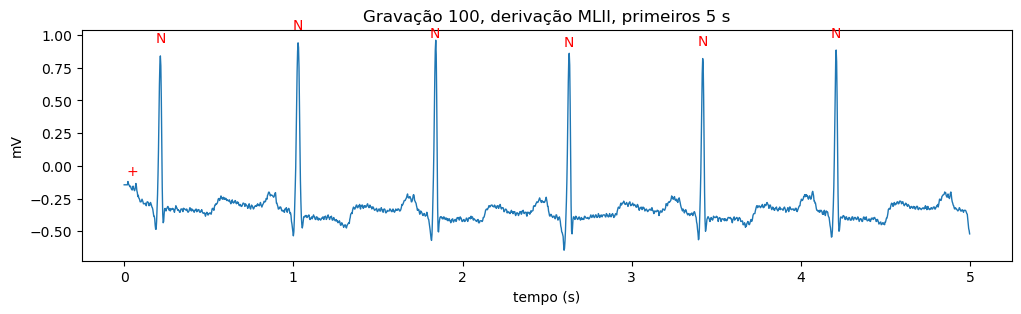

In [4]:
# Plota os primeiros 5 segundos da MLII com o símbolo de cada anotação
fs = registro.fs
canal = registro.sig_name.index("MLII")
n = 5 * fs
t = np.arange(n) / fs
sinal = registro.p_signal[:n, canal]

dentro = anotacao.sample < n
posicoes = anotacao.sample[dentro]
simbolos = np.array(anotacao.symbol)[dentro]

plt.figure(figsize=(12, 3))
plt.plot(t, sinal, lw=1)
for pos, simbolo in zip(posicoes, simbolos):
    plt.text(pos / fs, sinal[pos] + 0.1, simbolo, ha="center", color="red")
plt.xlabel("tempo (s)")
plt.ylabel("mV")
plt.title("Gravação 100, derivação MLII, primeiros 5 s")
plt.show()

In [5]:
# Quantas anotações de cada símbolo existem na gravação inteira
Counter(anotacao.symbol)

Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})

**Resultado do teste (05/11):** a leitura funciona. O sinal tem 360 Hz e duas derivações (MLII e V5), e cada anotação cai em cima do pico R, então dá para usar `anotacao.sample` como centro da janela de cada batimento. A gravação 100 tem 2.239 batimentos N, 33 A (classe S) e 1 V; o `+` é marca de ritmo e será descartado.

## 3. Montagem do dataset

Montamos o dataset com **uma linha por batimento**, usando as 44 gravações sem marcapasso (as mesmas nos dois splits, para a comparação ser justa). Ele fica em duas variáveis:

- `df`: tabela com `paciente` (gravação), `split` (DS1/DS2), `classe` (N/S/V/F/Q), `simbolo` original, `posicao` do pico R, `rr_anterior` e `rr_posterior` (segundos até o batimento anterior e até o próximo).
- `X`: matriz com o sinal; a linha `i` de `X` é a janela do batimento da linha `i` de `df`.

**Escolhas (provisórias, a confirmar com o Tom):**
- **Derivação MLII**, escolhida pelo nome. Na gravação 114 ela é o 2º canal, não o 1º.
- **Janela larga: 0,5 s antes e 0,5 s depois do pico R** (180 + 180 amostras). Cobre a onda P (antes do pico) e a onda T (depois). O tamanho final usado no modelo é recortado desta janela, então dá para testar tamanhos sem remontar o dataset.
- **Sinal em mV, sem normalizar.** A normalização é decidida na seção 5 (se for global, com estatísticas só do treino).
- **Só os 15 símbolos de batimento da tabela AAMI.** As outras anotações (`+` ritmo, `~` qualidade, `!` onda de flutter, comentários) são descartadas.
- **RR calculado com todos os batimentos da gravação.** O primeiro e o último batimento de cada gravação saem, porque não têm os dois RR.

O significado de cada símbolo foi conferido na tabela de anotações da própria `wfdb` (`wfdb.io.annotation.ann_label_table`).

In [6]:
# Símbolo do MIT-BIH -> classe AAMI EC57
MAPA_AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q",
}

# Gravações com marcapasso, excluídas do split por paciente
MARCAPASSO = ["102", "104", "107", "217"]

# Split por paciente de de Chazal et al. (2004)
DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]  # treino
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]  # teste

assert len(DS1) == 22 and len(DS2) == 22 and not set(DS1) & set(DS2)

In [7]:
GRAVACOES = DS1 + DS2
ANTES, DEPOIS = 180, 180  # amostras de cada lado do pico R (0,5 s a 360 Hz)

# Baixa as 44 gravações (só o que ainda não estiver na pasta). O print do wfdb é longo, então fica escondido.
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    wfdb.dl_database("mitdb", dl_dir=DADOS_DIR, records=GRAVACOES, annotators=["atr"])

In [8]:
def extrair_batimentos(gravacao):
    """Recorta a janela de cada batimento de uma gravação e calcula os intervalos RR."""
    registro = wfdb.rdrecord(f"{DADOS_DIR}/{gravacao}", channel_names=["MLII"])
    sinal = registro.p_signal[:, 0]
    anotacao = wfdb.rdann(f"{DADOS_DIR}/{gravacao}", "atr")

    simbolos = np.array(anotacao.symbol)
    eh_batimento = np.isin(simbolos, list(MAPA_AAMI))
    posicoes, simbolos = anotacao.sample[eh_batimento], simbolos[eh_batimento]
    rr = np.diff(posicoes) / registro.fs  # rr[k] = segundos entre o batimento k e o k+1

    linhas, janelas = [], []
    for k in range(1, len(posicoes) - 1):  # pula o primeiro e o último (sem RR dos dois lados)
        pos = posicoes[k]
        if pos - ANTES < 0 or pos + DEPOIS > len(sinal):
            continue
        janelas.append(sinal[pos - ANTES : pos + DEPOIS])
        linhas.append({"paciente": gravacao, "classe": MAPA_AAMI[simbolos[k]], "simbolo": simbolos[k],
                       "posicao": pos, "rr_anterior": rr[k - 1], "rr_posterior": rr[k]})
    return linhas, janelas

In [9]:
todas_linhas, todas_janelas = [], []
for gravacao in GRAVACOES:
    linhas, janelas = extrair_batimentos(gravacao)
    todas_linhas += linhas
    todas_janelas += janelas

df = pd.DataFrame(todas_linhas)
df["split"] = np.where(df["paciente"].isin(DS1), "DS1", "DS2")
X = np.array(todas_janelas, dtype=np.float32)

print("Batimentos:", len(df), "| formato de X:", X.shape)
df.head()

Batimentos: 100645 | formato de X: (100645, 360)


,paciente,classe,simbolo,posicao,rr_anterior,rr_posterior,split
0,101,N,N,396,0.869444,0.875000,DS1
1,101,N,N,711,0.875000,0.891667,DS1
2,101,N,N,1032,0.891667,0.933333,DS1
3,101,N,N,1368,0.933333,0.955556,DS1
4,101,N,N,1712,0.955556,0.900000,DS1


## 4. Análise exploratória (EDA)

Três perguntas antes de treinar qualquer modelo:
1. Quantos batimentos há de cada classe, e os números batem com a literatura?
2. A classe S depende de poucos pacientes?
3. As classes têm formato de onda e ritmo diferentes?

In [10]:
# Cores fixas por classe, iguais em todos os gráficos do notebook
CLASSES = ["N", "S", "V", "F"]
CORES = {"N": "#2a78d6", "S": "#eb6834", "V": "#1baf7a", "F": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})

### 4.1 Contagem por classe

O dataset tem **100.645 batimentos**. As contagens de S, V, F e Q batem com a literatura (diferença de no máximo 2); o N tem ~40 a menos em cada split porque descartamos o primeiro e o último batimento de cada gravação.

**89,5% dos batimentos são N** (o "83%" citado no plano inclui o MIT-BIH inteiro, com as gravações de marcapasso). Por isso acurácia não serve como métrica principal: chutar sempre N já dá ~90%. A classe Q tem só 15 batimentos e sai da avaliação, como previsto.

In [11]:
contagem = pd.crosstab(df["classe"], df["split"]).reindex(CLASSES + ["Q"])
contagem["DS1 (literatura)"] = [45866, 944, 3788, 415, 8]  # valores do CLAUDE.md (variam ±1-2 entre artigos)
contagem["DS2 (literatura)"] = [44259, 1837, 3221, 388, 7]
contagem["% do total"] = (100 * (contagem["DS1"] + contagem["DS2"]) / len(df)).round(1)
contagem

split,DS1,DS2,DS1 (literatura),DS2 (literatura),% do total
classe,,,,,
N,45824,44218,45866,44259,89.5
S,943,1836,944,1837,2.8
V,3788,3219,3788,3221,7.0
F,414,388,415,388,0.8
Q,8,7,8,7,0.0


### 4.2 Classe S por paciente

**A classe S está muito concentrada.** No teste (DS2), a gravação **232 sozinha tem 75%** dos batimentos S (1.381 de 1.836); 6 das 22 gravações não têm nenhum e outras 5 têm de 1 a 3. No treino (DS1), a 209 tem 41%.

Consequência: o recall de S no DS2 vai ser, na prática, "o quanto o modelo acerta o paciente 232". Por isso a análise por paciente (seção 7) é obrigatória para interpretar o resultado da classe S.

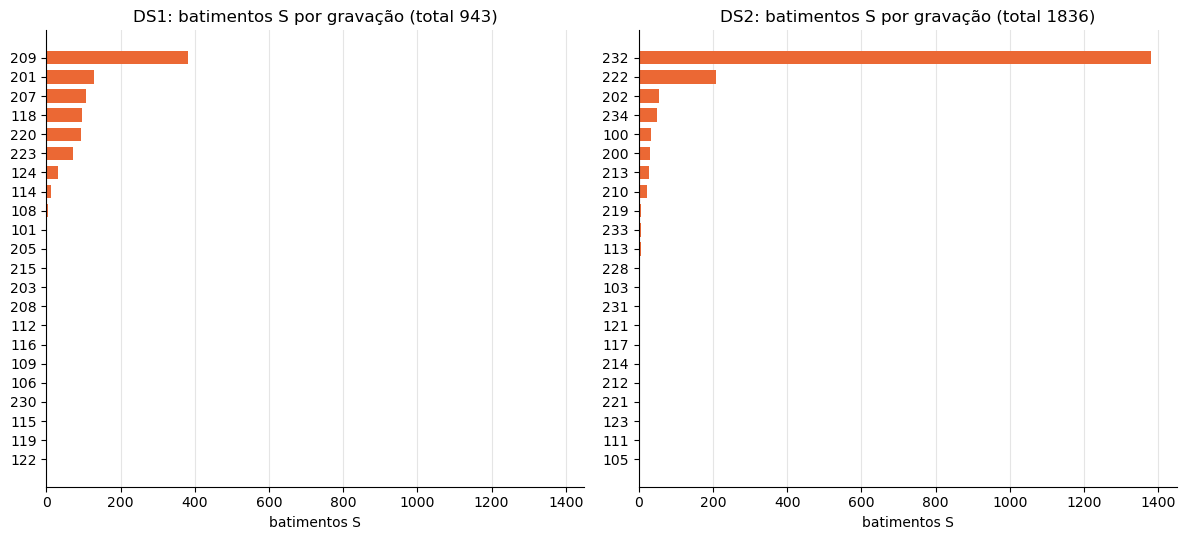

No DS2, a gravação 232 tem 1381 de 1836 batimentos S (75%).


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True)
for ax, (split, lista) in zip(eixos, [("DS1", DS1), ("DS2", DS2)]):
    n_s = df[(df["split"] == split) & (df["classe"] == "S")]["paciente"].value_counts()
    n_s = n_s.reindex(lista, fill_value=0).sort_values()
    ax.barh(n_s.index, n_s.values, color=CORES["S"], height=0.7)
    ax.set_title(f"{split}: batimentos S por gravação (total {n_s.sum()})")
    ax.set_xlabel("batimentos S")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

s_ds2 = df[(df["split"] == "DS2") & (df["classe"] == "S")]["paciente"].value_counts()
print(f"No DS2, a gravação {s_ds2.index[0]} tem {s_ds2.iloc[0]} de {s_ds2.sum()} batimentos S "
      f"({100 * s_ds2.iloc[0] / s_ds2.sum():.0f}%).")

### 4.3 Batimento médio por classe

**Como ler:** cada painel junta todos os batimentos de uma classe, alinhados pelo pico R (o 0 do eixo horizontal). A linha é a média, ou seja, o "batimento típico" da classe. A faixa clara mostra onde ficam os 50% de batimentos do meio (do 25º ao 75º percentil): faixa larga = batimentos muito diferentes entre si.

- **S tem formato quase igual ao N.** Só pela onda, separar S de N é difícil, e isso explica por que a S é a classe mais difícil.
- **V é a mais diferente e a mais variável** (faixa larga): o formato muda muito de paciente para paciente.
- **F tem formato próprio**, mas com poucos batimentos (802).

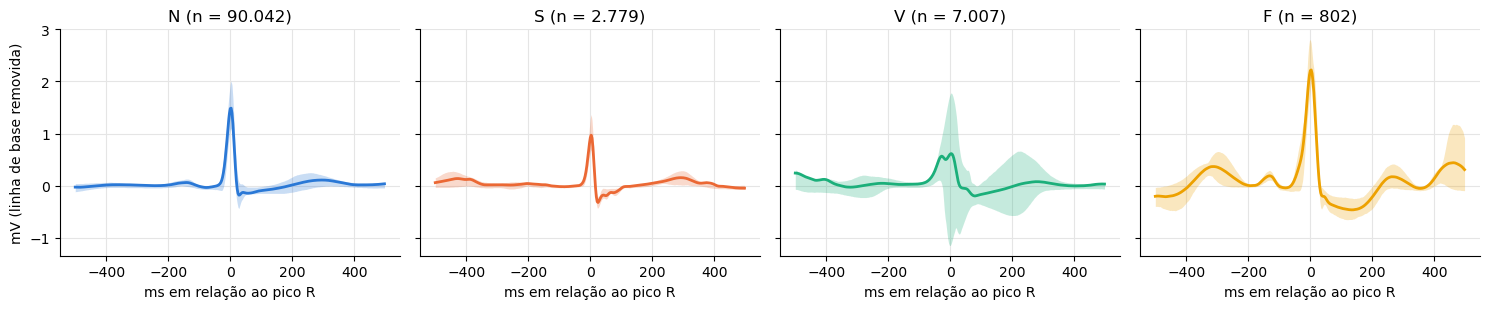

In [13]:
t_ms = np.arange(-ANTES, DEPOIS) / 360 * 1000  # tempo em ms, com o pico R em 0
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, classe in zip(eixos, CLASSES):
    janelas = X[df["classe"].values == classe]
    janelas = janelas - np.median(janelas, axis=1, keepdims=True)  # só para o gráfico: tira a linha de base
    p25, p75 = np.percentile(janelas, [25, 75], axis=0)
    ax.fill_between(t_ms, p25, p75, color=CORES[classe], alpha=0.25, lw=0)
    ax.plot(t_ms, janelas.mean(axis=0), color=CORES[classe], lw=2)
    ax.set_title(f"{classe} (n = {len(janelas):,})".replace(",", "."))
    ax.set_xlabel("ms em relação ao pico R")
eixos[0].set_ylabel("mV (linha de base removida)")
plt.tight_layout()
plt.show()

### 4.4 Intervalo RR por classe

**Como ler:** cada caixa resume o RR anterior (tempo desde o batimento anterior) de uma classe. O traço no meio é a mediana, a caixa contém os 50% de batimentos do meio e as hastes mostram a faixa típica (valores extremos omitidos). No gráfico da direita, 1,0 = o ritmo normal daquele paciente e 0,7 = chegou 30% antes do esperado.

- **RR cru (esquerda):** S chega um pouco antes que N, mas as caixas se sobrepõem bastante, porque cada paciente tem sua frequência cardíaca.
- **RR relativo ao ritmo da própria gravação (direita):** S fica claramente separado de N (mediana ~0,7 contra ~1,0), sem sobreposição das caixas.

Isso apoia a proposta do E5: dar ao modelo o RR **relativo ao ritmo do paciente**, já que é o ritmo, e não o formato, que distingue S de N. Aqui a média usa a gravação inteira, o que serve só para a EDA; no modelo, o certo é usar a média dos batimentos **anteriores**, como seria em tempo real.

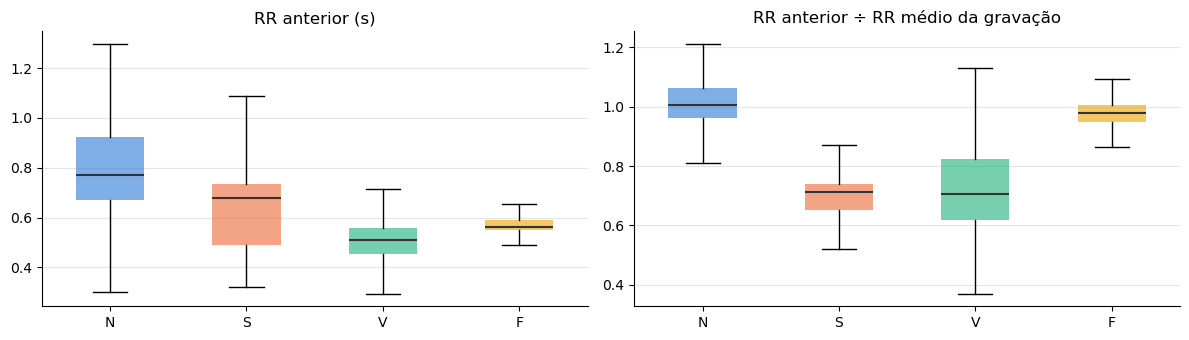

In [14]:
# Só para a EDA: RR anterior cru e dividido pelo RR médio da própria gravação
rr_relativo = df["rr_anterior"] / df.groupby("paciente")["rr_anterior"].transform("mean")

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, valores, titulo in [(eixos[0], df["rr_anterior"], "RR anterior (s)"),
                            (eixos[1], rr_relativo, "RR anterior ÷ RR médio da gravação")]:
    caixas = ax.boxplot([valores[df["classe"] == c] for c in CLASSES], tick_labels=CLASSES,
                        showfliers=False, patch_artist=True, widths=0.5,
                        medianprops={"color": "#333333", "lw": 1.5})
    for caixa, classe in zip(caixas["boxes"], CLASSES):
        caixa.set(facecolor=CORES[classe], alpha=0.6, lw=0)
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 5. Divisão dos dados

O ponto central do projeto. Fazemos dois splits da mesma tabela:

- **Aleatório por batimento:** batimentos do mesmo paciente caem no treino e no teste. É o que gera os resultados "bonitos".
- **Por paciente (DS1 → DS2):** o teste só tem pacientes que o modelo nunca viu. É o cenário real de um hospital.

A validação também é separada **por paciente**, dentro do DS1. Normalização, oversampling e escolha de hiperparâmetros usam só o treino.

**A fazer.**

## 6. Experimentos

Mudamos uma coisa por vez. As métricas principais são recall, precision e F1 **por classe** e o F1 macro. Acurácia geral aparece só como referência, porque ~83% dos batimentos são N.

**Tabela de experimentos** (preencher só com resultados rodados):

| Exp. | Configuração | Split | Recall S | Recall V | Recall F | F1 macro |
|---|---|---|---|---|---|---|
| E0 | Sempre "N" | por paciente | - | - | - | - |
| E1 | MLP | aleatório | - | - | - | - |
| E2 | MLP | por paciente | - | - | - | - |
| E3 | E2 + peso por classe | por paciente | - | - | - | - |
| E4 | E2 + oversampling (só treino) | por paciente | - | - | - | - |
| E5 | E2 + intervalo RR | por paciente | - | - | - | - |

### E0. Baseline "sempre N"

Mostra que uma acurácia alta não quer dizer nada aqui: chutar sempre "N" já acerta a maioria e erra todas as arritmias. **A fazer.**

### E1. MLP com split aleatório

Reproduz o resultado "bonito" da literatura. **A fazer.**

### E2. MLP com split por paciente

A mesma MLP do E1, agora avaliada em pacientes novos. A diferença entre E1 e E2 é o resultado principal do projeto. **A fazer.**

### E3. Peso por classe

Errar um batimento raro (S, V, F) passa a custar mais na loss do que errar um N. **A fazer.**

### E4. Oversampling

Repete batimentos das classes raras, **só no treino e depois do split**. **A fazer.**

### E5. Intervalo RR como entrada

Um batimento S costuma chegar antes do esperado, e o formato da onda sozinho não mostra isso. Adicionamos o tempo até o batimento anterior e até o próximo. **A fazer.**

## 7. Análise de erros (classe S)

Onde a classe S falha: matriz de confusão, desempenho por paciente do DS2 e exemplos de batimentos S classificados como N. **A fazer.**

## 8. Conclusões e limitações

**A fazer**, depois dos experimentos.

## Bônus

Só se o núcleo estiver pronto. Candidatos: Conv1D, Grad-CAM/saliency (não visto nas aulas), focal loss, teste no INCART.